In [ ]:
import xarray as xr
from matplotlib import pyplot as plt

In [ ]:
ds_true = xr.open_mfdataset(["/work/ka1176/shared_data/2025-wwm-emulator-schism/combined/out2d_35.nc", "/work/ka1176/shared_data/2025-wwm-emulator-schism/combined/out2d_36.nc"])

/tmp/ipykernel_3895546/3110944369.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_true = xr.open_mfdataset(["/work/ka1176/shared_data/2025-wwm-emulator-schism/combined/out2d_35.nc", "/work/ka1176/shared_data/2025-wwm-emulator-schism/combined/out2d_36.nc"])


In [ ]:
ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict/runs/2025-11-20_13-31-08/predictions.nc")

In [ ]:
ds_pred

<xarray.Dataset> Size: 373MB
Dimensions:               (time: 290, nSCHISM_hgrid_node: 311243)
Coordinates:
  * time                  (time) datetime64[ns] 2kB 2020-02-04T00:05:00 ... 2...
  * nSCHISM_hgrid_node    (nSCHISM_hgrid_node) int64 2MB 0 1 2 ... 311241 311242
    SCHISM_hgrid_node_x   (nSCHISM_hgrid_node) float64 2MB ...
    SCHISM_hgrid_node_y   (nSCHISM_hgrid_node) float64 2MB ...
    nSCHISM_hgrid_node_x  (nSCHISM_hgrid_node) float64 2MB ...
    nSCHISM_hgrid_node_y  (nSCHISM_hgrid_node) float64 2MB ...
Data variables:
    sigWaveHeight         (time, nSCHISM_hgrid_node) float32 361MB ...
Attributes:
    description:  Predictions for sigWaveHeight
    checkpoint:   ./logs/train/runs/2025-11-20_10-09-49/simple-wwm-emulator/a...
    model:        src.model.WWMEmulator.WWMEmulator

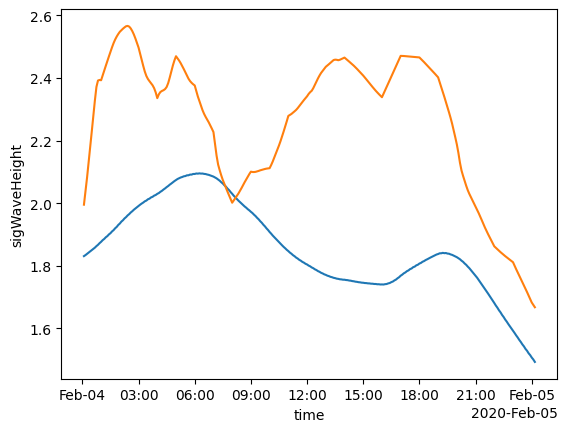

In [ ]:
ds_true["sigWaveHeight"].mean(dim="nSCHISM_hgrid_node").plot()
ds_pred["sigWaveHeight"].mean(dim="nSCHISM_hgrid_node").plot()

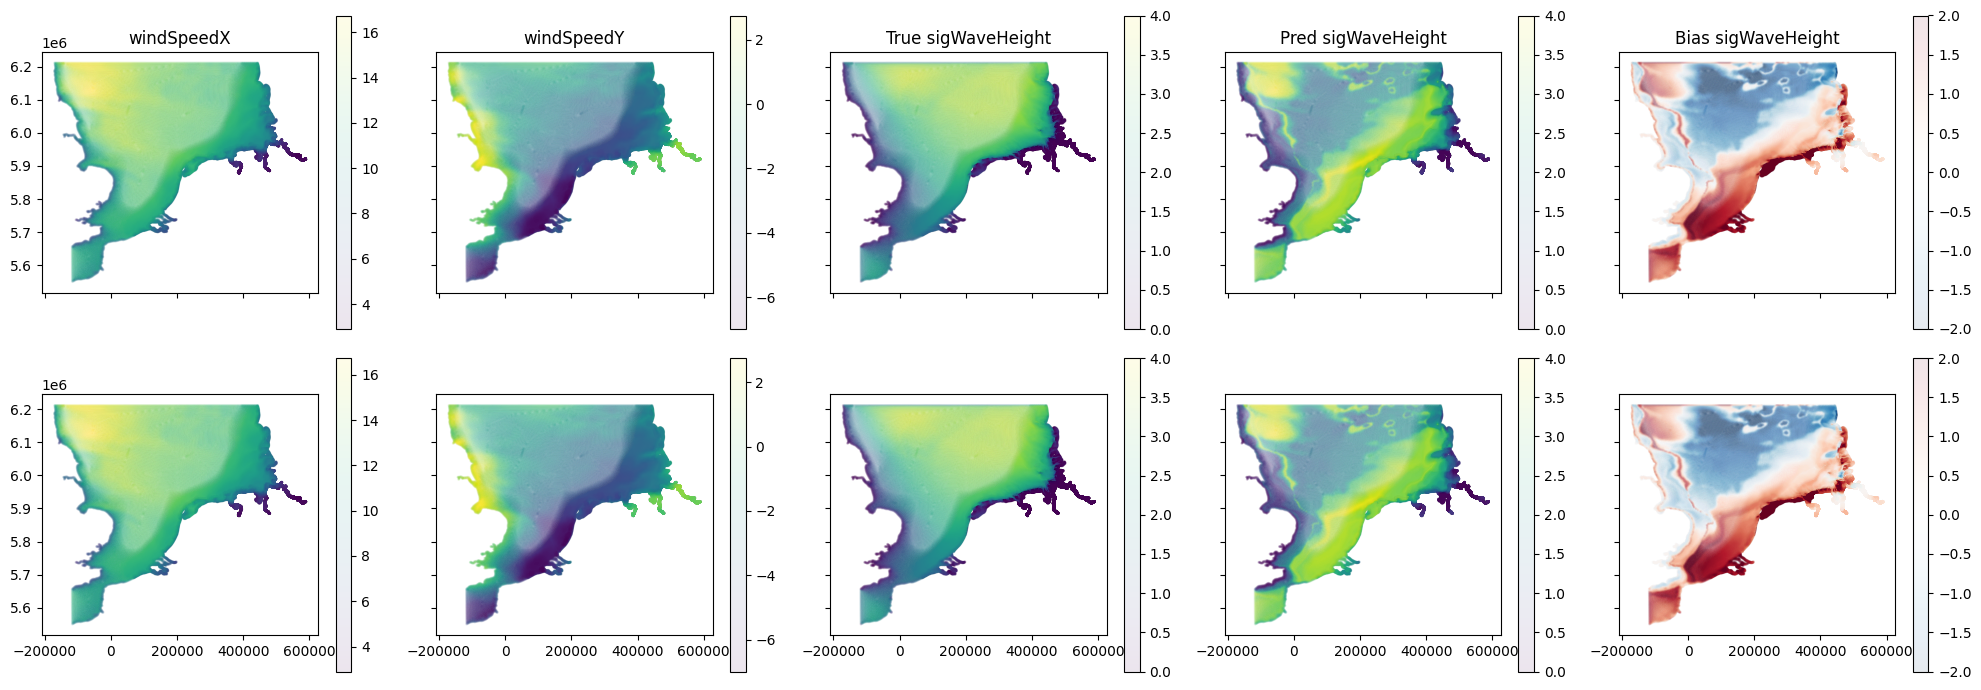

In [ ]:
fig, ax = plt.subplots(2, 5, sharex=True, sharey=True, figsize=(20, 7))

time_ix = [10, 200]

nx = ds_pred.SCHISM_hgrid_node_x.values
ny = ds_pred.SCHISM_hgrid_node_y.values

for i, tt in enumerate(time_ix):

    ct = ds_true.isel(time=10)["sigWaveHeight"].values
    cp = ds_pred.isel(time=10)["sigWaveHeight"].values

    x1 = ds_true.isel(time=10)["windSpeedX"].values
    x2 = ds_true.isel(time=10)["windSpeedY"].values

    img=ax[i, 0].scatter(nx, ny, c=x1, alpha=0.1, marker="o", s=1)
    plt.colorbar(img, ax=ax[i, 0])
    
    img=ax[i, 1].scatter(nx, ny, c=x2, alpha=0.1, marker="o", s=1)
    plt.colorbar(img, ax=ax[i, 1])
    
    
    img=ax[i, 2].scatter(nx, ny, c=ct, alpha=0.1, marker="o", s=1, vmin=0, vmax=4)
    plt.colorbar(img, ax=ax[i, 2])
    
    img=ax[i, 3].scatter(nx, ny, c=cp, alpha=0.1, marker="o", s=1, vmin=0, vmax=4)
    plt.colorbar(img, ax=ax[i, 3])

    img=ax[i, 4].scatter(nx, ny, c=cp-ct, alpha=0.1, marker="o", s=1, vmin=-2, vmax=+2, cmap="RdBu_r")
    plt.colorbar(img, ax=ax[i, 4])

[axx.set_aspect("equal") for axx in ax.flatten()]
ax[0, 0].set_title("windSpeedX")
ax[0, 1].set_title("windSpeedY")
ax[0, 2].set_title("True sigWaveHeight")
ax[0, 3].set_title("Pred sigWaveHeight")
ax[0, 4].set_title("Bias sigWaveHeight")
fig.tight_layout() 